### LINEAR REGRESSION 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Advertising.csv')

In [3]:
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


### Domain Analysis
1. TV - Amount spend on TV advertisment
2. Radio - Amount spend on Radio
3. Newspaper - Amount spend on Newspaper
4. Sales - Sales of product

In [4]:
df.tail()

,Unnamed: 0,TV,Radio,Newspaper,Sales
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5
199,200,232.1,8.6,8.7,13.4


In [5]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [6]:
df.drop(['Unnamed: 0'], axis = 1, inplace = True)

In [7]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


### Explarotory Data Analysis (EDA)

<Axes: xlabel='TV', ylabel='Count'>

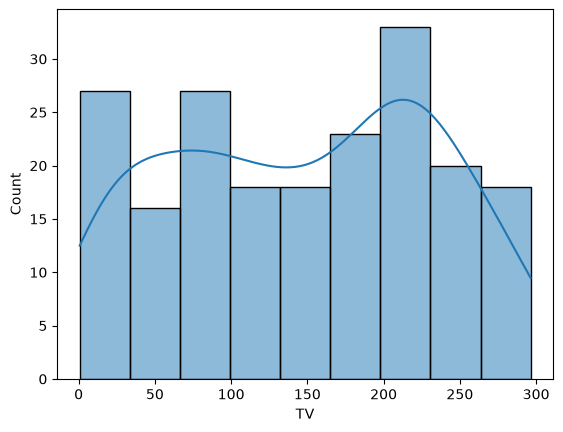

In [8]:
# Univariate Analysis -- is the analysis done on 1 var/ 1 col at a time
#Analyzing TV
sns.histplot(x = df['TV'], kde = True)

<Axes: xlabel='TV', ylabel='Sales'>

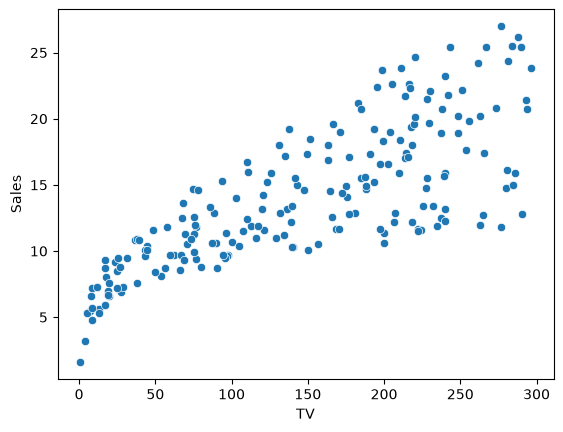

In [9]:
# Bivariate Analysis -- is the analysis done on 2 var/ 2 col at a time
# This step is performed when input and output are known.
# Analyzing TV and Sales
sns.scatterplot(x = 'TV', y = 'Sales', data = df)
# The more marketing on TV is leading to more sales in the product.

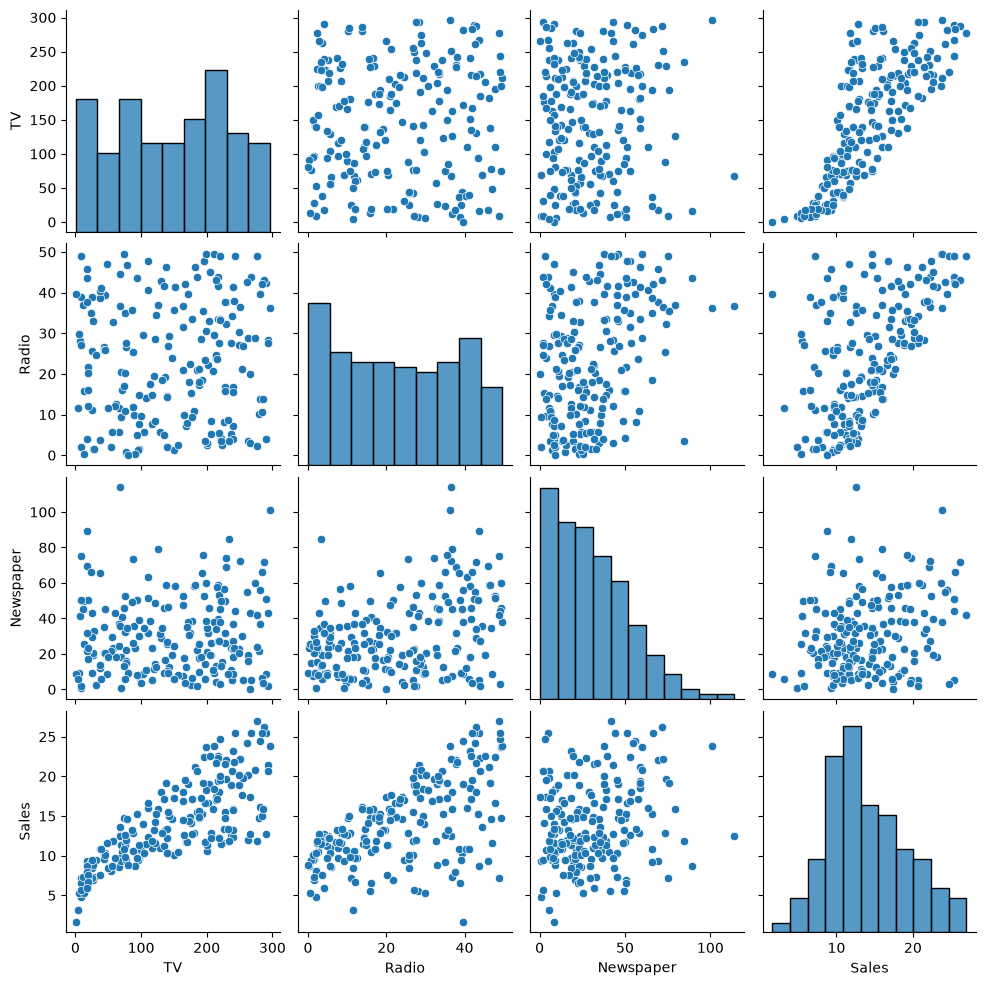

In [10]:
# Multivariate Analysizing -- is the analysis done on more than 2 var/ 2 col at a time
sns.pairplot(df)

<Axes: >

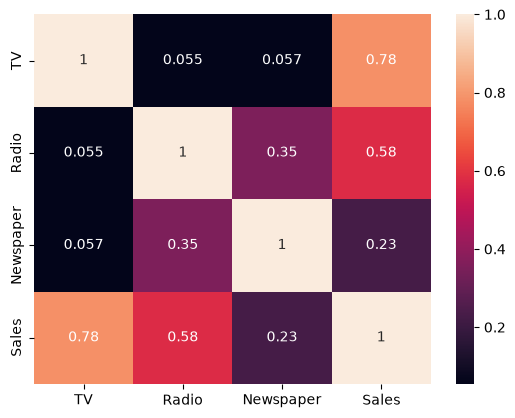

In [11]:
## Step 2 Checking the correlation
hm = df.corr()
sns.heatmap(data = hm, annot = True)

In [12]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

<Axes: xlabel='TV'>

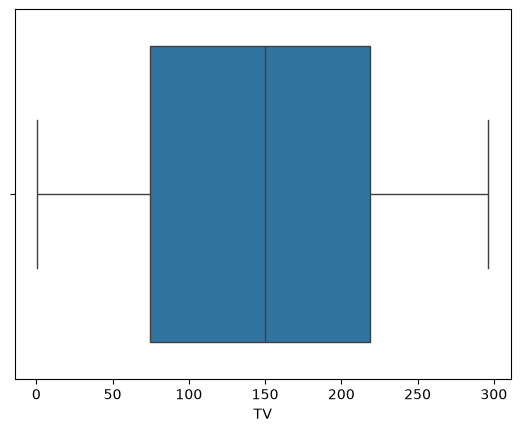

In [13]:
# check the outliers -- by using BOXPLOT
sns.boxplot(x = 'TV', data = df)

<Axes: xlabel='Radio'>

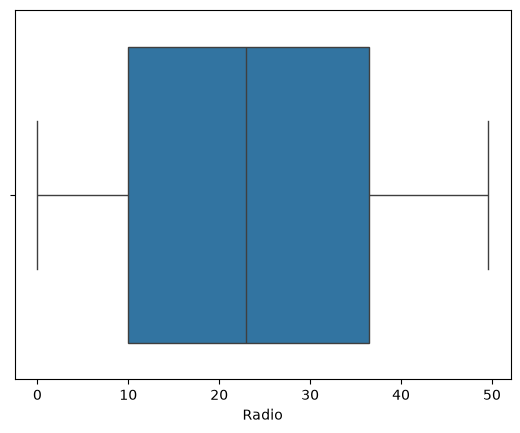

In [14]:
sns.boxplot(x = 'Radio', data = df)

<Axes: xlabel='Newspaper'>

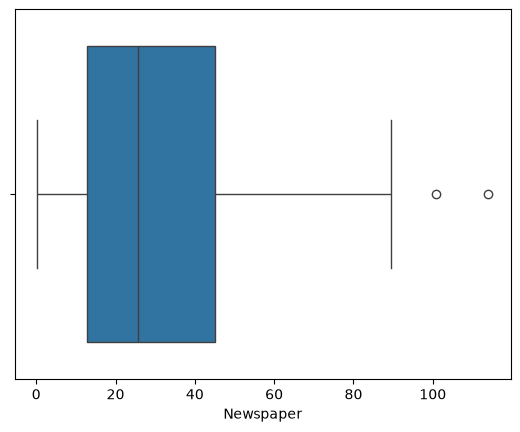

In [15]:
sns.boxplot(data = df, x = 'Newspaper')

- we have outliers in Newspaper col handle them 
- But before handling them we need to find them
- we have 2 ways to find it ---
1. IQR method (when data is not NORMALLY distributed)
2. 3 Sigma Rule (when data is NORMALLY distributed)

- lower limit = Q1 - 1.5* IQR
- upper limit = Q3 + 1.5* IQR
- (draw box plot to show)
- Use IQR to find outliers  -- why??? 
- bcoz here our data doesn't following a ND if u observe the histplots 

In [16]:
from scipy import stats

In [17]:
stats.iqr(df['Newspaper'])

np.float64(32.35)

In [18]:
Q1 = df['Newspaper'].quantile(0.25)
print(f"Lower Quartile is : {Q1}")
Q3 = df['Newspaper'].quantile(0.75)
print(f"Upper Quartile is : {Q3}")

Lower Quartile is : 12.75
Upper Quartile is : 45.1


In [19]:
IQR = Q3 - Q1
print(f"IQR is : {IQR}")

IQR is : 32.35


In [20]:
lower_limit = Q1 - 1.5 * IQR
print(f"Lower Limit is : {lower_limit}")
upper_limit = Q3 + 1.5 * IQR
print(f"Upper Limit is : {upper_limit}")

Lower Limit is : -35.775000000000006
Upper Limit is : 93.625


In [21]:
df[(df.Newspaper > lower_limit) & (df.Newspaper < upper_limit)]

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [22]:
# Find outliers which are below lower limit
df.loc[df['Newspaper'] < lower_limit]
# Find outliers which are above upper limit
df.loc[df['Newspaper'] > upper_limit]

,TV,Radio,Newspaper,Sales
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


- Handling data -- 2 ways
  1. Drop those rows which has outliers
  2. Impute the outliers
- ( impute means replace -- by mean (if it follows ND) or by median (if it follows skewness)

- as we already see that newspaper col has a right skewed data .. we use median

- Replace outliers with median cause data is not ND 

In [23]:
df.loc[df['Newspaper'] > upper_limit] = df['Newspaper'].median()
df.loc[df['Newspaper'] > upper_limit]

,TV,Radio,Newspaper,Sales


In [24]:
#Step 1 Independent and dependent variable creation
x = df[['TV','Radio','Newspaper']] ## X variable contains all inputs
# x = data.drop('Sales',axis=1)
y = df.Sales ## y is output

- Step 2 Traning and testing data creation
-  We split data into train and test to check if our model is actually learning or just memorizing.
    1. Train data -- used to teach the model
    2. Test data -- used to check performance

- for this we need to discuss new library called sklearn 
- !pip install scikit-learn

In [25]:
import sklearn
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 43)

In [26]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [27]:
model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [28]:
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.04, 0.18,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.912
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [29]:
y_predict = model.predict(x_test)

In [30]:
y_test

56      5.5
37     14.7
67     13.4
79     11.0
80     11.8
188    15.9
183    26.2
10      8.6
128    24.7
62     15.7
65      9.3
17     24.4
133    19.6
195     7.6
146    13.2
38     10.1
173    11.7
149    10.1
93     22.2
29     10.5
0      22.1
2       9.3
122    11.6
180    10.5
95     16.9
121     7.0
185    22.6
39     21.5
66      9.5
19     14.6
11     17.4
45     14.9
41     17.1
92     19.4
168    17.1
1      10.4
57     13.2
189     6.7
151    11.6
167    12.2
116    12.2
138     9.6
155     3.2
82     11.3
160    14.4
181    12.2
171    14.5
12      9.2
55     23.7
77     14.2
22      5.6
129     9.7
105    19.2
102    14.8
159    12.9
9      10.6
15     22.4
150    16.1
76      6.9
119     6.6
Name: Sales, dtype: float64

In [31]:
y_predict

array([ 9.22728513, 15.95732239, 12.36894368, 10.08544033, 11.93893005,
       18.41938048, 23.56744568,  7.64384827, 22.15105159, 16.66215141,
        8.50953047, 22.7485889 , 19.09279033,  6.13386615, 15.26129715,
       10.49245303, 12.20921045, 10.45466125, 20.83152025,  9.64379742,
       20.21484996, 12.80750478, 13.65480865, 10.90456853, 16.3468877 ,
        8.48910942, 20.72231626, 20.26605613,  9.75922382, 14.40020999,
       17.30061979, 15.25173865, 17.31192964, 18.94615183, 17.02920251,
       12.83356437, 13.07946672,  6.82785835, 10.31529552, 13.43622495,
       12.26267418, 10.40245792,  6.20008429, 10.66885985, 14.33454565,
       13.92845124, 14.44601743, 11.10507192, 21.0896853 , 14.14919792,
        7.18816153,  8.43607912, 17.98991524, 17.40079601, 12.66751501,
       12.65618866, 20.6597231 , 18.05683126,  5.26980099,  7.58139519])

In [32]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import math
print(f"R2 Score is: {r2_score(y_test, y_predict)}")
print(f"Mean Squared Error is: {mean_squared_error(y_test, y_predict)}")
rmse = math.sqrt(mean_squared_error(y_test, y_predict))
print(f"Root Mean Squared Error is: {rmse}")
print(f"Mean Absolute Error is: {mean_absolute_error(y_test, y_predict)}")

R2 Score is: 0.9187709472596854
Mean Squared Error is: 2.3366301927664797
Root Mean Squared Error is: 1.5286040012921855
Mean Absolute Error is: 1.2112019276462471
